# 01 · Build the Wikispeedia world

**Why.** The benchmark needs a frozen copy of Wikipedia in which we know every page the agent can see and every link it can click. Only then are the shortest paths, and the information measures built on them, exact.

**What.** We use [Wikispeedia](https://snap.stanford.edu/data/wikispeedia.html) (West & Leskovec), a 4,604-article snapshot of the 2007 *Wikipedia for Schools* selection. It comes with the rendered HTML of every article and the link graph. It also has about 76,000 games of this exact task played by people, which will serve as a human baseline. The notebook:

1. downloads the raw files into `data/raw/wikispeedia/` (about 800 MB; only the article HTML is unpacked);
2. renders each article to plain text that keeps every internal link as a character span;
3. cuts the text into chunks (the part of the page the agent sees at once);
4. writes the world to `data/worlds/wikispeedia/`;
5. checks the rendered links against the dataset's own link list and its shortest-path matrix.

**Runtime.** About 15 s on a laptop, excluding the download.

In [1]:
import json, os, re, subprocess, time, urllib.parse as up
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wikigame.world import ROOT, parse_wikispeedia_html, write_world, World
from wikigame.metrics import Graphs, bfs_to
from wikigame import style

RAW = ROOT / "data" / "raw" / "wikispeedia"
SNAP = "https://snap.stanford.edu/data/wikispeedia/"
CHUNK_CHARS = 2000   # characters the agent sees at once: about one screen, ~450 tokens

## Download

The graph archive is 10 MB. The HTML archive is 790 MB, mostly images, so only the article `.htm` files are unpacked from it.

In [2]:
RAW.mkdir(parents=True, exist_ok=True)
for f in ["wikispeedia_paths-and-graph.tar.gz", "wikispeedia_articles_html.tar.gz"]:
    if not (RAW / f).exists():
        subprocess.run(["curl", "-sSfL", "-o", str(RAW / f), SNAP + f], check=True)
if not (RAW / "wikispeedia_paths-and-graph").exists():
    subprocess.run(["tar", "xzf", "wikispeedia_paths-and-graph.tar.gz"], cwd=RAW, check=True)
if not (RAW / "wpcd").exists():
    subprocess.run(["tar", "xzf", "wikispeedia_articles_html.tar.gz", "--include=wpcd/wp/*.htm"], cwd=RAW, check=True)

GRAPH = RAW / "wikispeedia_paths-and-graph"
read_tsv = lambda name, cols: pd.read_csv(GRAPH / name, sep="\t", comment="#", header=None, names=cols, quoting=3)
titles = read_tsv("articles.tsv", ["title"])["title"].tolist()
print(len(titles), "articles")

4604 articles


## Render every article

The article body sits between the `start content` and `end content` markers of each HTML file. Inside it, we keep the text of paragraphs, headings (written `## Heading`), list items (`- item`), table rows (cells separated by `|`) and image captions. We drop scripts, reference markers and the *Wikipedia for Schools* banner. A link is kept only if it points to one of the 4,604 articles, because those are the only pages that exist in this world.

Article ids in `articles.tsv` are percent-encoded once (`%C3%85land`), while file names and link targets are encoded twice. So we match fully decoded names.

In [3]:
decoded = {up.unquote(t): i for i, t in enumerate(titles)}
files = {}
for d, _, fs in os.walk(RAW / "wpcd" / "wp"):
    for f in fs:
        if f.endswith(".htm"):
            files[up.unquote(up.unquote(f[:-4]))] = Path(d) / f

HREF = re.compile(r"^\.\./\.\./wp/[^/]+/(.+)\.htm$")
def target_of(href):
    m = HREF.match(href)
    return decoded.get(up.unquote(up.unquote(m.group(1)))) if m else None

t0 = time.time()
pages = []
for t in titles:
    html = files[up.unquote(t)].read_text(encoding="utf-8", errors="replace")
    pages.append(parse_wikispeedia_html(html, target_of))
print(f"rendered {len(pages)} pages in {time.time() - t0:.0f} s")

rendered 4604 pages in 10 s


In [4]:
world = write_world("wikispeedia", titles, pages, CHUNK_CHARS)
p = world.index["Rhine"]
page = world.page(p)
print(f"{page['name']}: {len(page['text']):,} characters, {len(page['chunks'])} chunks, {len(page['links'])} link occurrences, {len(world.out_links(p))} distinct targets\n")
from wikigame.env import render_chunk
print(render_chunk(world, page, 0))

Rhine: 24,301 characters, 14 chunks, 99 link occurrences, 53 distinct targets

Rhine River

The Rhine is one of the most important rivers in [Europe](Europe)

Origin | Grisons, [Switzerland](Switzerland)
Mouth | [North Sea](North Sea), Hoek van Holland, the Netherlands
Basin countries | [Switzerland](Switzerland), [Italy](Italy), [Liechtenstein](Liechtenstein), [Austria](Austria), [Germany](Germany), [France](France), [Luxembourg](Luxembourg), [Netherlands](Netherlands)
Length | 1,320 km (820 mi)
Source elevation | Vorderrhein: approx. 2,600 m (8,500 ft)
Hinterrhein: approx. 2,500 m (8,200 ft)
Avg. discharge | [Basel](Basel): 1,060 m³/s (37,440 ft³/s)
Strasbourg: 1,080 m³/s (38,150 ft³/s)
[Cologne](Cologne): 2,090 m³/s (73,820 ft³/s)
[Dutch](Netherlands) border: 2,260 m³/s (79,823 ft³/s)
Basin area | 185,000 km² (71,430 mi²)

Loreley

The River Rhine ([Dutch](Dutch language) Rijn, [French](French language) Rhin, [German](German language) Rhein, Italian: Reno, Romansch: Rein, ) is one o

## Check the rendered links against the dataset

The dataset ships its own link list (`links.tsv`). If our rendering keeps exactly the links a reader can click, the two edge sets should agree. Disagreement would mean that we either show links the dataset does not count or hide links it does.

In [5]:
ref = read_tsv("links.tsv", ["src", "dst"])
ref_edges = set(zip(ref.src.map(world.index), ref.dst.map(world.index)))
our_edges = {(p, q) for p in range(world.n) for q in world.out_links(p)}
print(f"links.tsv: {len(ref_edges):,} edges · rendered: {len(our_edges):,} edges · in both: {len(ref_edges & our_edges):,}")
only_ref, only_ours = ref_edges - our_edges, our_edges - ref_edges
print("only in links.tsv:", len(only_ref), [(world.name_of(a), world.name_of(b)) for a, b in list(only_ref)[:5]])
print("only rendered:    ", len(only_ours), [(world.name_of(a), world.name_of(b)) for a, b in list(only_ours)[:5]])

links.tsv: 119,882 edges · rendered: 119,780 edges · in both: 119,748
only in links.tsv: 134 [('Renormalization', 'Renormalization'), ('Logic', 'Logic'), ('Pterosaur', 'Pterosaur'), ('Super Mario 64', 'China'), ('List of sovereign states', 'Flag of Mexico')]
only rendered:     32 [('List of sovereign states', 'Éire'), ('Stockholm', 'Åland'), ('British Isles (terminology)', 'Éire'), ('Columba', 'Áedán mac Gabráin'), ('Edgar Allan Poe', 'Édouard Manet')]


The dataset also ships the shortest-path length between every pair of articles. We recompute distances by breadth-first search for 300 random targets, once on the dataset's own edge list (this checks our distance code) and once on our rendered graph (this shows how much the small edge differences above move the distances).

In [6]:
rows = [l.strip() for l in open(GRAPH / "shortest-path-distance-matrix.txt") if l.strip() and not l.startswith("#")]
M = np.array([[(-1 if ch == "_" else int(ch)) for ch in r] for r in rows])   # M[source, target]
g = Graphs.build(world)
ref_src, ref_dst = np.array([e for e in ref_edges if e[0] != e[1]]).T
rng = np.random.default_rng(0)
mismatch = {"rendered graph": 0, "links.tsv graph": 0}
for t in rng.choice(world.n, 300, replace=False):
    mismatch["rendered graph"] += int(np.sum(bfs_to(world.n, g.page_src, g.page_dst, np.array([t])) != M[:, t]))
    mismatch["links.tsv graph"] += int(np.sum(bfs_to(world.n, ref_src, ref_dst, np.array([t])) != M[:, t]))
print(f"distance mismatches over {300 * world.n:,} (source, target) pairs:", mismatch)

distance mismatches over 1,381,200 (source, target) pairs: {'rendered graph': 297, 'links.tsv graph': 15}


On the dataset's own edge list, the distance code reproduces the matrix except for 15 pairs. All of them start at list pages (such as *List of countries*) that link to *Éire* or *Åland*. The matrix counts those links while `links.tsv` lost them to an encoding problem, and our rendered graph keeps them. The 297 mismatches on the rendered graph come from the same accented links plus the image-only links (a flag picture that links to *Flag of Mexico*), which a text-only agent cannot see and we therefore leave out. Self-links are also left out, since following one does not move the player.

## What the agent sees

Each page is cut into chunks of at most 2,000 characters (about one screen of text). Cuts fall on line breaks when possible and never inside a link. The figures show how long pages are, how many chunks they have, and how many distinct links an agent can click in a single chunk. Chunks with no links force the agent to scroll. The figure is also saved to `docs/figures/world_stats.png` for the documentation.

pages                             4604
states (page, chunk)             53697
edges (page graph)              119780
edges (state graph)             251069
pages without outgoing links        17
pages without incoming links       469
dtype: int64

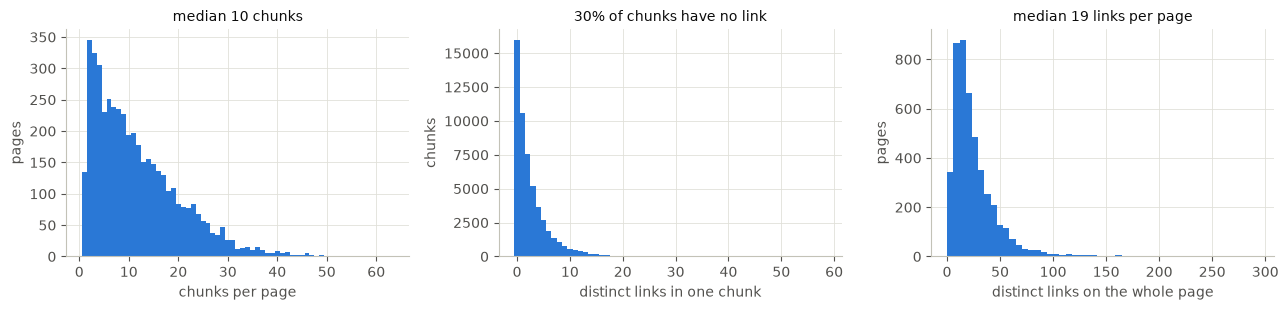

In [7]:
style.use()
n_chunks = np.array([world.n_chunks(p) for p in range(world.n)])
links_per_chunk = np.array([len(c) for p in range(world.n) for c in world.chunk_links[p]])
out_deg = np.array([len(world.out_links(p)) for p in range(world.n)])
in_deg = np.bincount(g.page_dst, minlength=world.n)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(n_chunks, bins=np.arange(1, n_chunks.max() + 2) - 0.5, color=style.BLUE)
ax[0].set(xlabel="chunks per page", ylabel="pages", title=f"median {np.median(n_chunks):.0f} chunks")
ax[1].hist(links_per_chunk, bins=np.arange(0, 60) - 0.5, color=style.BLUE)
ax[1].set(xlabel="distinct links in one chunk", ylabel="chunks", title=f"{np.mean(links_per_chunk == 0):.0%} of chunks have no link")
ax[2].hist(out_deg, bins=50, color=style.BLUE)
ax[2].set(xlabel="distinct links on the whole page", ylabel="pages", title=f"median {np.median(out_deg):.0f} links per page")
plt.tight_layout()
style.save(fig, "world_stats")

summary = pd.Series({
    "pages": world.n, "states (page, chunk)": int(n_chunks.sum()), "edges (page graph)": len(g.page_src),
    "edges (state graph)": len(g.state_src), "pages without outgoing links": int(np.sum(out_deg == 0)),
    "pages without incoming links": int(np.sum(in_deg == 0)),
})
summary